## Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pint
from open_atmos_jupyter_utils import show_plot

si = pint.UnitRegistry()
si.setup_matplotlib(True)

## Diffusion of $CO_2$ in air

- $N_A = 6.022 * 10^{23}$  [1/mol]
- $R = 8.3145$ [J/(mol K)]
- $\eta = 0.0218$ [Pa*s]
- $T = 298.15$ [K]
- $r = 1.65 * 10^{-12}$ [m]
- $D_{CO_2} = 0.164 * 10^{-2}$ [m$^2$/s]

In [2]:
# TODO change to informative names, create constants catalogue
Na = 6.022 * 10**23 / si.mole
R = 8.31 * si.joule / si.kelvin / si.mole
eta = 14.9 * 10 ** (-6) * si.pascal * si.s
T = 298.15 * si.K
r = 165 * 10 ** (-12) * si.m
D = 0.164 * 10 ** (-4) * si.m**2 / si.s

t = 300 * si.s
dt = 0.1 * si.s

mu = 0 * si.m
sigma = np.sqrt(2 * dt * D)

## Two-dimensional trajectories of brownian motion

In [3]:
steps = int(t / dt)
num_trajectories = 10000

jumps = (
    np.random.normal(
        loc=mu / si.m, scale=sigma / si.m, size=(2, steps, num_trajectories)
    )
    * si.m
)
trajectories = jumps.cumsum(axis=1)

In [4]:
# same as above but as a function
def generator(t, dt, num_trajectories, dim=1):
    steps = int(t / dt)
    jumps = (
        np.random.normal(
            loc=mu / si.m, scale=sigma / si.m, size=(dim, steps, num_trajectories)
        )
        * si.m
    )
    trajectories = jumps.cumsum(axis=1)
    return trajectories

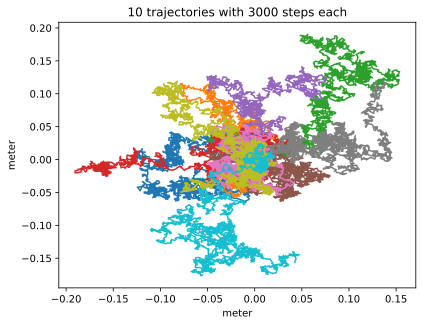

In [5]:
n_plot = 10
fig, ax = plt.subplots()
ax.plot(
    trajectories[0, :, :n_plot], trajectories[1, :, :n_plot]
)  # plot only first n_plot=10 trajectories
ax.set_title(f"{n_plot} trajectories with {steps} steps each")
show_plot(f"{n_plot}_trajectories")

## Histogram -- porównanie z teoretyczną wartością rozkładu normalnego(0,1)

In [6]:
def pdf(x, mu, sigma):
    """Probability density function for normal distribution with mu and sigma."""
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-((x - mu) ** 2) / (2 * sigma**2))

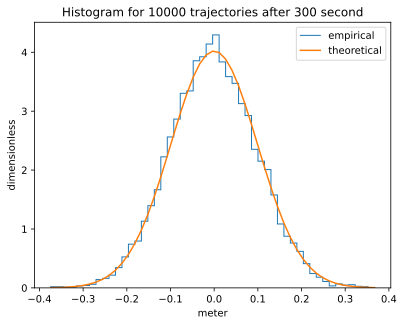

In [7]:
fig, ax = plt.subplots()
values, bins_edges = np.histogram(
    trajectories[0, steps - 1, :].to(si.m).magnitude, bins=50, density=True
)
ax.stairs(values=values, edges=bins_edges * si.m, label="empirical")
ax.plot(
    bins_edges * si.m,
    pdf(bins_edges, mu=mu / si.m, sigma=np.sqrt(steps) * sigma / si.m).to_base_units(),
    label="theoretical",
)
ax.set_title(f"Histogram for {num_trajectories} trajectories after {t}")
ax.legend()
show_plot("histogram")

Dla kilku punktów w czasie

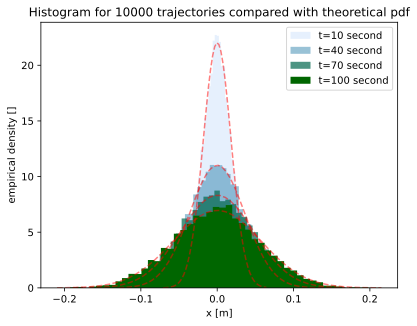

In [8]:
fig, ax = plt.subplots()
end_time = 100 * si.s
num_trajectories = 10000
timepoints = np.linspace(10 * si.s, end_time, 4)
trajectories = generator(end_time, dt, num_trajectories, dim=1)

for time in timepoints:
    n = int(time / dt)
    t_to_end_time = float(time / end_time)
    values, bins_edges = np.histogram(
        trajectories[0, n - 1, :].to(si.m).m, bins=50, density=True
    )
    ax.stairs(
        values,
        bins_edges * si.m,
        label=f"t={time:.3g}",
        fill=True,
        color=(0, 0.4, 1 - t_to_end_time),
        alpha=t_to_end_time,
    )
    ax.plot(
        bins_edges,
        pdf(bins_edges, mu=mu / si.m, sigma=np.sqrt(n) * sigma / si.m).to_base_units(),
        color="r",
        linestyle="--",
        alpha=0.5,
    )
ax.set_xlabel(f"x [{ax.xaxis.units:~P}]")
ax.set_ylabel(f"empirical density [{ax.yaxis.units:~P}]")
ax.set_title(
    f"Histogram for {num_trajectories} trajectories compared with theoretical pdf"
)
ax.legend()
show_plot("histogram")

## Diffusion coefficient from data

In [9]:
t = 300 * si.s
dt = 0.1 * si.s
num_trajectories = 100000
trajectories = generator(end_time, dt, num_trajectories, dim=1)

In [10]:
D_empirical = np.mean(trajectories[0, -1, :] ** 2) / 2 / end_time
print(
    f"Teoretyczne D={D.to_base_units():.3g}\nEmpiryczne D={D_empirical.to_base_units():.3g}"
)

Teoretyczne D=1.64e-05 meter ** 2 / second
Empiryczne D=1.63e-05 meter ** 2 / second


# This formula is only correct if medium is a liquid

In [11]:
Na_empirical = R * T / (6 * np.pi * eta * r * D_empirical)
print(f"Teoretyczne Na={Na:.3g}\nEmpiryczne Na={Na_empirical.to_base_units():.3g}")

Teoretyczne Na=6.02e+23 / mole
Empiryczne Na=3.28e+21 / mole
